# Clasificación de estado (bueno / normal / crítico) — Zenit

Este notebook toma las variables de telemetría de `data.csv` y calcula, para
cada observación, un **estado de salud**: `bueno`, `normal` o `crítico`.

**Problema a resolver:** Zenit va a tener muchos usuarios (activos
on-premise, DigitalOcean, Azure, AWS, con perfiles de carga muy distintos).
Un umbral fijo como "CPU > 80 % = crítico" funciona para un activo y es
completamente erróneo para otro que trabaja normalmente al 85 % de CPU. Por
eso este notebook **no usa umbrales absolutos fijos**: calcula, para cada
`activo`, una **línea base estadística propia** a partir de su propio
historial (mediana y dispersión robusta), y clasifica cada observación según
cuántas "desviaciones típicas" está esa observación por encima de lo que es
normal *para ese activo en particular*.

Esto es justamente lo que pide RF-DET-03 del ERS de Zenit ("la detección
parte de una línea base estadística propia... medida contra la verdad de
referencia del laboratorio antes de introducir métodos más complejos") y
respeta la restricción R-05: no se usa un umbral de infraestructura sacado
de la literatura (ej. "80 % de CPU"), sino un criterio puramente
estadístico (qué tan atípico es el valor respecto al propio historial),
que por construcción se adapta a cualquier usuario.

**Salida del notebook:** una función reutilizable que recibe telemetría de
*cualquier* activo/usuario de Zenit (con las mismas columnas) y devuelve una
columna `estado` con los tres valores pedidos, sin necesidad de retocar
números a mano por cliente.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

df = pd.read_csv("data.csv")
df["time"] = pd.to_datetime(df["time"])
df = df.sort_values(["activo", "time"]).reset_index(drop=True)

print(df.shape)
df.head()

(17280, 18)


,time,activo,cpu_user,cpu_system,cpu_wait,carga_1m,memoria_used,disco_used_frac,disco_bytes_s,red_bytes_s,paginacion_s,procesos_running,tasa_llamadas_pedidos,tasa_llamadas_catalogo,tasa_errores_pedidos,ref_fase,ref_uid,ref_tipo_eval
0,2026-10-06 00:00:00+00:00,activo-do-nodo-01,0.164329,0.050100,0.002004,0.57,0.205797,0.137209,NaN,NaN,NaN,2.0,NaN,NaN,NaN,montaje,NaN,NaN
1,2026-10-06 00:00:10+00:00,activo-do-nodo-01,0.179635,0.036503,0.000961,0.48,0.209096,0.137210,116369.599246,20279.178953,465476.762928,1.0,24.300656,50.501363,4.800130,montaje,NaN,NaN
2,2026-10-06 00:00:20+00:00,activo-do-nodo-01,0.175097,0.034047,0.000000,0.41,0.209374,0.137210,2866.589371,19736.643674,11466.645415,1.0,20.300877,36.501577,4.000173,montaje,NaN,NaN
3,2026-10-06 00:00:30+00:00,activo-do-nodo-01,0.187379,0.044660,0.000000,0.65,0.209021,0.137211,15150.428509,20889.288580,60603.755485,1.0,25.299823,53.499626,4.999965,montaje,NaN,NaN
4,2026-10-06 00:00:40+00:00,activo-do-nodo-01,0.203373,0.044643,0.000992,0.55,0.215255,0.137211,37698.695216,22774.486115,150789.889957,1.0,23.798560,49.497006,4.699716,montaje,NaN,NaN


## 1. Exploración rápida

`activo` identifica el nodo/recurso (en despliegues reales habrá muchos
valores distintos, uno o más por usuario de Zenit). Las columnas `ref_fase`,
`ref_uid` y `ref_tipo_eval` son la **verdad de referencia** del laboratorio de
fallos (RF-LAB): marcan en qué fase está el ensayo y, si hay una inyección de
fallo activa, de qué tipo es. No existen en telemetría real de un cliente;
solo están aquí para poder validar el resultado al final del notebook
(sección 5). El clasificador en sí **no las usa**.

In [2]:
print("Activos distintos en este archivo:", df["activo"].nunique())
print(df["activo"].unique())
print()
print("Rango temporal:", df["time"].min(), "a", df["time"].max())
print()
print("Nulos por columna:")
print(df.isna().sum())

Activos distintos en este archivo: 1
<StringArray>
['activo-do-nodo-01']
Length: 1, dtype: str

Rango temporal: 2026-10-06 00:00:00+00:00 a 2026-10-07 23:59:50+00:00

Nulos por columna:
time                          0
activo                        0
cpu_user                      0
cpu_system                    0
cpu_wait                      0
carga_1m                      0
memoria_used                  0
disco_used_frac               0
disco_bytes_s                 1
red_bytes_s                   1
paginacion_s                  1
procesos_running              0
tasa_llamadas_pedidos         1
tasa_llamadas_catalogo        1
tasa_errores_pedidos          1
ref_fase                      0
ref_uid                   15886
ref_tipo_eval             15886
dtype: int64


## 2. Métricas a monitorear

Se definen las señales de infraestructura sobre las que se calcula el
estado. Para todas, "más alto es peor" (saturación de CPU, memoria, disco,
red, paginación, procesos en cola, errores). Se añade una métrica derivada,
`tasa_error_relativa`, que normaliza los errores de pedidos contra el
volumen de llamadas: así un usuario con mucho tráfico y uno con poco tráfico
quedan en la misma escala (proporción, no conteo bruto).

`cpu_total` resume `cpu_user + cpu_system` (tiempo de CPU realmente
consumido por el sistema). Las primeras filas de cada activo tienen `NaN`
en las columnas calculadas como tasa (requieren una lectura previa); se
rellenan por activo.

In [3]:
df["cpu_total"] = df["cpu_user"] + df["cpu_system"]

llamadas = df["tasa_llamadas_pedidos"].replace(0, np.nan)
df["tasa_error_relativa"] = (df["tasa_errores_pedidos"] / llamadas).fillna(0.0)

METRICAS = [
    "cpu_total",
    "cpu_wait",
    "carga_1m",
    "memoria_used",
    "disco_used_frac",
    "disco_bytes_s",
    "red_bytes_s",
    "paginacion_s",
    "procesos_running",
    "tasa_error_relativa",
]

df[METRICAS] = df.groupby("activo")[METRICAS].transform(lambda s: s.ffill().bfill())

df[METRICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
cpu_total,17280.0,0.196841,9.674923e-02,0.057344,0.133937,0.188129,0.233936,9.970150e-01
cpu_wait,17280.0,0.000091,7.269297e-04,0.000000,0.000000,0.000000,0.000000,3.125000e-02
carga_1m,17280.0,0.379942,3.094288e-01,0.010000,0.190000,0.310000,0.490000,5.490000e+00
memoria_used,17280.0,0.218395,4.754461e-02,0.180214,0.211328,0.214021,0.215904,7.091420e-01
disco_used_frac,17280.0,0.171355,1.078065e-01,0.137209,0.149305,0.149497,0.149589,8.400410e-01
disco_bytes_s,17280.0,29002.136710,5.662683e+05,0.000000,2867.971745,9011.139697,14742.619266,3.492002e+07
red_bytes_s,17280.0,18899.906124,8.543625e+03,583.178228,10633.750697,19487.801817,25888.593312,7.514836e+04
paginacion_s,17280.0,116306.909434,2.273183e+06,0.000000,11471.896441,36045.891144,58969.858409,1.399974e+08
procesos_running,17280.0,1.465509,1.019443e+00,1.000000,1.000000,1.000000,2.000000,1.900000e+01
tasa_error_relativa,17280.0,0.197529,3.968521e-02,0.000000,0.194915,0.197309,0.198052,1.000000e+00


## 3. Línea base estadística por activo

Para cada `activo` y cada métrica se calculan dos estadísticos sobre su
propio historial:

- **mediana**: el valor "típico" de esa métrica para ese activo.
- **escala**: una medida robusta de dispersión alrededor de la mediana
  (MAD — *median absolute deviation* — reescalada para que sea comparable a
  una desviación estándar; si la métrica es demasiado plana para que el MAD
  sea útil, como ocurre con señales que casi siempre valen 0, se usa la
  desviación estándar como respaldo).

Con esos dos números se construye, para cada observación, una versión
robusta del puntaje Z clásico:

```
z = (valor_observado - mediana_del_activo) / escala_del_activo
```

`z` responde a la pregunta "¿cuántas desviaciones típicas por encima de lo
normal está este activo ahora mismo?", y es comparable entre activos aunque
sus escalas absolutas sean completamente distintas (bytes/s de un nodo
pequeño vs. uno grande, por ejemplo). La clasificación por métrica es:

- `bueno` si `z < Z_NORMAL`
- `normal` si `Z_NORMAL <= z < Z_CRITICO`
- `critico` si `z >= Z_CRITICO`

Se usan los cortes convencionales de la literatura estadística para el
z-score robusto (Iglewicz & Hoaglin), **no** umbrales de infraestructura:
`Z_NORMAL = 1.5`, `Z_CRITICO = 3.5`. Son los parámetros que un administrador
podría ajustar por cliente si lo necesita (HU-52, "ajustar los umbrales...
para adaptar las alertas al comportamiento real de mis servicios"), sin
tocar el resto del código.

In [4]:
Z_NORMAL = 1.5
Z_CRITICO = 3.5


def calcular_baseline(data, metricas):
    '''Calcula, por activo y métrica, la mediana y la escala (dispersión
    robusta) que definen la línea base estadística de cada activo.

    Devuelve un DataFrame indexado por `activo` con columnas
    '<metrica>__mediana' y '<metrica>__escala'.
    '''
    filas = []
    for activo, grupo in data.groupby("activo"):
        fila = {"activo": activo}
        for metrica in metricas:
            serie = grupo[metrica]
            mediana = serie.median()
            mad = (serie - mediana).abs().median() * 1.4826
            desviacion = serie.std()
            escala = mad if mad > 0 else desviacion
            fila[f"{metrica}__mediana"] = mediana
            fila[f"{metrica}__escala"] = escala if escala and escala > 0 else np.nan
        filas.append(fila)
    return pd.DataFrame(filas).set_index("activo")


def clasificar_estado(data, baseline, metricas, z_normal=Z_NORMAL, z_critico=Z_CRITICO):
    '''Añade a `data` una columna de estado por métrica (`estado_<metrica>`)
    y una columna `estado` combinada: la más severa entre todas las
    métricas monitoreadas para esa fila.
    '''
    data = data.merge(baseline, left_on="activo", right_index=True, how="left")

    orden = {"bueno": 0, "normal": 1, "critico": 2}
    peor = pd.Series("bueno", index=data.index, dtype="object")
    peor_rank = pd.Series(0, index=data.index)

    for metrica in metricas:
        mediana = data[f"{metrica}__mediana"]
        escala = data[f"{metrica}__escala"]
        z = (data[metrica] - mediana) / escala
        # un activo sin escala (métrica constante en su historial) no aporta
        # señal de desviación: se trata como z = 0 (bueno) en vez de romper.
        z = z.fillna(0.0)

        estado_m = np.select(
            [z >= z_critico, z >= z_normal],
            ["critico", "normal"],
            default="bueno",
        )
        estado_m = pd.Series(estado_m, index=data.index)
        estado_m[data[metrica].isna() | mediana.isna()] = np.nan

        data[f"estado_{metrica}"] = estado_m

        rank_m = estado_m.map(orden).fillna(0)
        mas_severo = rank_m > peor_rank
        peor = peor.where(~mas_severo, estado_m)
        peor_rank = peor_rank.where(~mas_severo, rank_m)

    data["estado"] = peor
    data = data.drop(columns=baseline.columns)
    return data


baseline = calcular_baseline(df, METRICAS)
baseline.filter(like="cpu_total").join(baseline.filter(like="memoria_used"))

,cpu_total__mediana,cpu_total__escala,memoria_used__mediana,memoria_used__escala
activo,,,,
activo-do-nodo-01,0.188129,0.075,0.214021,0.00325


## 4. Clasificación final

Se aplica la línea base sobre todo el dataset. La columna `estado` es la
clasificación pedida (`bueno` / `normal` / `critico`); las columnas
`estado_<métrica>` quedan disponibles para explicar *por qué* una fila
quedó en determinado estado (qué señal concreta disparó la alerta), útil
para el diagnóstico explicable de Zenit (RF-DIA).

In [5]:
df_clasificado = clasificar_estado(df, baseline, METRICAS)

print(df_clasificado["estado"].value_counts())
print()
print(df_clasificado["estado"].value_counts(normalize=True).mul(100).round(2).astype(str) + " %")

estado
bueno      10717
normal      4403
critico     2160
Name: count, dtype: int64

estado
bueno      62.02 %
normal     25.48 %
critico     12.5 %
Name: proportion, dtype: str


In [6]:
cols_mostrar = ["time", "activo", "cpu_total", "memoria_used", "disco_used_frac",
                "tasa_error_relativa", "estado"]
df_clasificado.loc[df_clasificado["estado"] == "critico", cols_mostrar].head(10)

,time,activo,cpu_total,memoria_used,disco_used_frac,tasa_error_relativa,estado
0,2026-10-06 00:00:00+00:00,activo-do-nodo-01,0.214429,0.205797,0.137209,0.000000,critico
1,2026-10-06 00:00:10+00:00,activo-do-nodo-01,0.216138,0.209096,0.137210,0.197531,critico
11,2026-10-06 00:01:50+00:00,activo-do-nodo-01,0.304391,0.185513,0.137226,0.197674,critico
12,2026-10-06 00:02:00+00:00,activo-do-nodo-01,0.242273,0.187802,0.137242,0.675159,critico
13,2026-10-06 00:02:10+00:00,activo-do-nodo-01,0.575176,0.222615,0.137248,0.972477,critico
14,2026-10-06 00:02:20+00:00,activo-do-nodo-01,0.189708,0.209072,0.137248,0.302013,critico
21,2026-10-06 00:03:30+00:00,activo-do-nodo-01,0.303951,0.205180,0.137251,0.198847,critico
25,2026-10-06 00:04:10+00:00,activo-do-nodo-01,0.214644,0.205354,0.137253,0.197425,critico
26,2026-10-06 00:04:20+00:00,activo-do-nodo-01,0.439000,0.248300,0.137261,0.197719,critico
27,2026-10-06 00:04:30+00:00,activo-do-nodo-01,0.987039,0.281226,0.137966,0.195833,critico


## 5. Visualización

Serie de tiempo de uso de CPU para el activo del archivo, coloreando cada
punto según el estado calculado, junto con las líneas de umbral (mediana +
`Z_NORMAL` y mediana + `Z_CRITICO`) propias de ese activo.

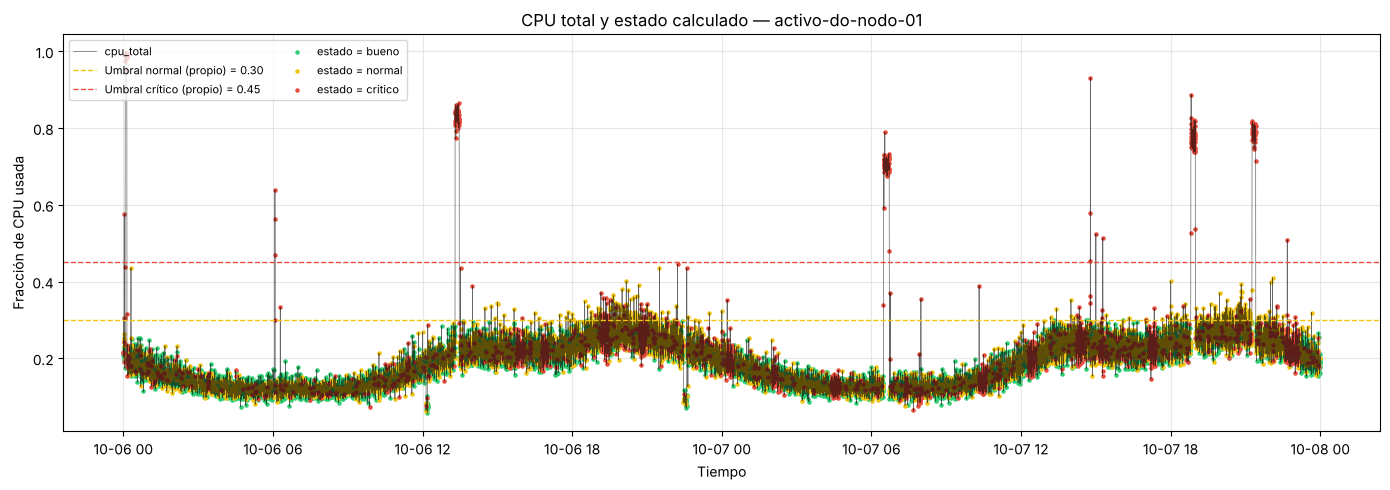

In [7]:
activo_ejemplo = df_clasificado["activo"].iloc[0]
muestra = df_clasificado[df_clasificado["activo"] == activo_ejemplo].set_index("time")

mediana = baseline.loc[activo_ejemplo, "cpu_total__mediana"]
escala = baseline.loc[activo_ejemplo, "cpu_total__escala"]
umbral_normal = mediana + Z_NORMAL * escala
umbral_critico = mediana + Z_CRITICO * escala

color_estado = {"bueno": "#2ecc71", "normal": "#f1c40f", "critico": "#e74c3c"}

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(muestra.index, muestra["cpu_total"], color="black", linewidth=0.5, alpha=0.6, label="cpu_total")
ax.axhline(umbral_normal, color="#f1c40f", linestyle="--", linewidth=1,
           label=f"Umbral normal (propio) = {umbral_normal:.2f}")
ax.axhline(umbral_critico, color="#e74c3c", linestyle="--", linewidth=1,
           label=f"Umbral crítico (propio) = {umbral_critico:.2f}")

for estado, color in color_estado.items():
    tramo = muestra["estado"] == estado
    ax.scatter(muestra.index[tramo], muestra["cpu_total"][tramo], s=5, color=color, label=f"estado = {estado}")

ax.set_title(f"CPU total y estado calculado — {activo_ejemplo}")
ax.set_xlabel("Tiempo")
ax.set_ylabel("Fracción de CPU usada")
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

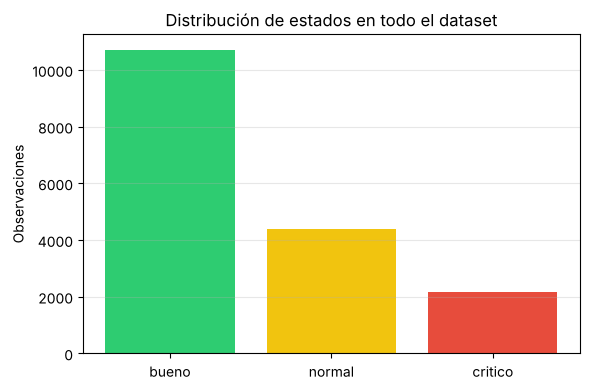

In [8]:
conteo = df_clasificado["estado"].value_counts().reindex(["bueno", "normal", "critico"]).fillna(0)

plt.figure(figsize=(6, 4))
plt.bar(conteo.index, conteo.values, color=[color_estado[e] for e in conteo.index])
plt.title("Distribución de estados en todo el dataset")
plt.ylabel("Observaciones")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Granularidad de 1 minuto (opcional)

Según la arquitectura de Zenit, la detección de anomalías corre sobre el
resumen por minuto (`zenit_1m`), no sobre el dato crudo cada 10 s. Esta
sección repite el cálculo a esa granularidad: suele dar un estado más
estable (menos alternancia entre bueno/normal/critico fila a fila), que es
lo que terminaría viendo el operador en el tablero.

In [9]:
df_1m = (
    df.set_index("time")
      .groupby("activo")[METRICAS]
      .resample("1min")
      .mean()
      .reset_index()
)

baseline_1m = calcular_baseline(df_1m, METRICAS)
df_1m_clasificado = clasificar_estado(df_1m, baseline_1m, METRICAS)

df_1m_clasificado["estado"].value_counts()

estado
bueno      1660
normal      763
critico     457
Name: count, dtype: int64

## 7. Validación exploratoria contra la verdad de referencia

`data.csv` viene del laboratorio de fallos (RF-LAB): mientras `ref_fase`
vale `campana`, puede haber una inyección activa (`ref_tipo_eval` no nulo).
Esto permite una comprobación rápida: ¿con qué frecuencia el estado
`critico` calculado coincide con una inyección de fallo real?

Esto **no reemplaza** la evaluación formal de RF-LAB-05 (precisión,
exhaustividad, medida F, tiempo medio hasta la detección contra la verdad de
referencia completa); es solo una señal rápida de que el enfoque de línea
base propia por activo tiene sentido antes de pasar a los métodos no
supervisados más complejos que pide RF-DET-08. Por R-05 del ERS, no se fija
una meta previa: el número que salga aquí es la línea base de este método,
no un objetivo a cumplir.

In [10]:
if df_clasificado["ref_tipo_eval"].notna().any():
    es_fallo_real = df_clasificado["ref_tipo_eval"].notna()
    es_critico = df_clasificado["estado"] == "critico"

    vp = (es_critico & es_fallo_real).sum()
    fp = (es_critico & ~es_fallo_real).sum()
    fn = (~es_critico & es_fallo_real).sum()
    vn = (~es_critico & ~es_fallo_real).sum()

    precision = vp / (vp + fp) if (vp + fp) else float("nan")
    exhaustividad = vp / (vp + fn) if (vp + fn) else float("nan")
    f1 = (2 * precision * exhaustividad / (precision + exhaustividad)
          if (precision + exhaustividad) else float("nan"))

    print(f"Verdaderos positivos:  {vp}")
    print(f"Falsos positivos:      {fp}")
    print(f"Falsos negativos:      {fn}")
    print(f"Verdaderos negativos:  {vn}")
    print()
    print(f"Precisión:      {precision:.2%}")
    print(f"Exhaustividad:  {exhaustividad:.2%}")
    print(f"Medida F1:      {f1:.2%}")

    print()
    print("Desglose por tipo de fallo inyectado (proporción de filas en cada estado):")
    print(
        df_clasificado.loc[es_fallo_real]
        .groupby("ref_tipo_eval")["estado"]
        .value_counts(normalize=True)
        .unstack()
        .round(3)
    )
else:
    print("Este archivo no trae columna de verdad de referencia utilizable; se omite la validación.")

Verdaderos positivos:  1309
Falsos positivos:      851
Falsos negativos:      85
Verdaderos negativos:  15035

Precisión:      60.60%
Exhaustividad:  93.90%
Medida F1:      73.66%

Desglose por tipo de fallo inyectado (proporción de filas en cada estado):
estado         bueno  critico  normal
ref_tipo_eval                        
caida          0.492    0.398   0.110
cpu            0.004    0.985   0.011
disco_abrupto  0.004    0.987   0.009
disco_gradual  0.003    0.992   0.005
memoria          NaN    0.988   0.012


La detección funciona bien para fallos que *elevan* una señal (CPU,
disco, memoria): casi todas esas filas quedan en `critico`. El caso
`caida` (caída de servicio) es más débil, porque una caída puede manifestarse
como una **baja** de tráfico/CPU en vez de una subida, y este clasificador
solo mira desviaciones hacia arriba. Es una limitación esperable de un
primer método estadístico univariante (RF-DET-03) y es exactamente la razón
por la que el ERS pide pasar después a aprendizaje no supervisado sobre las
series completas (RF-DET-08): ahí sí se puede capturar que "nada se mueve
cuando algo debería moverse" como anomalía.

## 8. Guardar la línea base para reutilizarla

La tabla `baseline` (mediana y escala por activo y métrica) se guarda en
disco. Para clasificar telemetría nueva del mismo activo no hace falta
recalcular nada: se carga esta tabla y se llama a
`clasificar_estado(data_nueva, baseline, METRICAS)`. Para un
**usuario/activo nuevo de Zenit** que todavía no tiene baseline propia,
basta con correr `calcular_baseline` sobre su propio historial — el resto
del notebook es idéntico, porque el método no depende de ninguna cifra fija,
solo de los datos de cada activo.

Siguiendo RF-DET-05, conviene reentrenar (recalcular) esta baseline
periódicamente a medida que se acumula más historial por activo.

In [11]:
import pickle

with open("baseline_estado_zenit.pkl", "wb") as f:
    pickle.dump({"baseline": baseline, "metricas": METRICAS,
                 "z_normal": Z_NORMAL, "z_critico": Z_CRITICO}, f)

print("Baseline guardada en baseline_estado_zenit.pkl")

Baseline guardada en baseline_estado_zenit.pkl


## 9. Resumen

- El estado (`bueno` / `normal` / `critico`) se calcula por fila, comparando
  cada métrica contra una línea base de mediana + dispersión robusta
  (MAD, con respaldo en desviación estándar) **del propio historial de cada
  `activo`**, no contra números fijos de infraestructura.
- El estado final de la fila es el más severo entre todas las métricas
  monitoreadas (CPU, espera de CPU, carga, memoria, disco, red, paginación,
  procesos, error relativo de pedidos).
- Como cada activo trae su propia línea base, el mismo código sirve para
  cualquier usuario de Zenit sin importar el tamaño de su infraestructura o
  su volumen de tráfico: lo que cambia es el historial de datos de entrada,
  no el código ni los umbrales.
- Contra la verdad de referencia del laboratorio de fallos de este archivo,
  el método detecta con buena exhaustividad los fallos que saturan un
  recurso (CPU, disco, memoria), y es más débil frente a caídas de servicio
  (que bajan una señal en vez de subirla) — una limitación documentada, no
  escondida.
- Próximo paso natural, ya previsto en el ERS: pasar de este método
  estadístico (RF-DET-03) a aprendizaje no supervisado sobre las series
  (RF-DET-08), y comparar ambos contra la verdad de referencia del
  laboratorio de fallos (RF-LAB-05).